In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import scipy.sparse as sparse
import scipy.sparse.linalg as linalg

In [ ]:
class PGG():
    def __init__(
        self,
        Z = 200,                    # Population
        ZR = 40,                    # Rich population
        bR = 2.5,                   # Rich endowment
        bP = 0.625,                 # Poort endowment
        c = 0.1,                    # Contribution rate
        N = 6,                      # Group size
        M = 3,                      # Threshold parameter
        beta = 3.0,                 # Parameter for stationary distribution
        mu = -1.0,                  # Exploration probability
        h = 0.0,                    # Homophily
        r = 0.2,                    # Risk
        r_obs = 0.0,                # Rich bbstination rate
        p_obs = 0.0                 # Poor obstination rate
    ):
        self.Z = Z
        self.ZR = ZR
        self.ZP = Z - ZR
        self.bR = bR
        self.bP = bP
        self.c = c
        self.N = N
        self.M = M
        self.beta = beta
        self.r_obs_count = int(r_obs * ZR)
        self.p_obs_count = int(p_obs * (Z - ZR))
        
        if mu == -1: self.mu = 1/Z
        else: self.mu = mu

        self.h = h
        self.r = r

        self.cR = c * bR
        self.cP = c * bP
        self.b_mean = (ZR / Z) * bR + ((Z-ZR) / Z) * bP

    def heaviside(self, k: float) -> int:
        return 1 if k >= 0 else 0

    def expected_payoff(self, isRich: bool, cooperation: bool, jr: int, jp: int) -> float:
        b = self.bR if isRich else self.bP
        cRP = self.cR if isRich else self.cP
        delta = self.cR * jr + self.cP * jp - self.M * self.c * self.b_mean
        defection_payoff = b * (self.heaviside(delta) + (1-self.r) * (1-self.heaviside(delta)))
        if not cooperation: 
            return defection_payoff
        else:
            return defection_payoff - cRP

    def helper_fitness(self, a: int, b: int, c: int, isRich: bool, cooperation: bool) -> float:
        # If the pool of available people (a, b, or c) is negative, 
        # it means this group composition is impossible. Return 0.
        if a < 0 or b < 0 or c < 0:
            return 0.0
        
        res = 0

        jR_addend = 0
        jP_addend = 0

        if cooperation and isRich: jR_addend = 1
        elif cooperation and not isRich: jP_addend = 1

        for jR in range(self.N):
            for jP in range(self.N - jR):
                foo = self.N - 1 -  jR - jP
                res += (math.comb(a, jR) * math.comb(b, jP) * math.comb(c, foo) * self.expected_payoff(isRich, cooperation, jR + jR_addend, jP + jP_addend))

        return res
                

    def fitness(self, isRich: bool, cooperation: bool, iR: int, iP: int) -> float:
        a, b, c = 0, 0, 0

        if cooperation:
            c = self.Z - iR - iP
        else:
            a = iR
            b = iP
            c = self.Z - 1 - iR - iP

        if isRich and cooperation:
            a = iR - 1
            b = iP
        elif not isRich and cooperation:
            a = iR
            b = iP - 1

        ftns = (1 / math.comb(self.Z - 1, self.N - 1)) * self.helper_fitness(a, b, c, isRich, cooperation)

        return ftns
    
    def fermi_function(self, fit_x: float, fit_y: float) -> float:
        return 1 / (1 + np.exp(self.beta * (fit_x - fit_y)))
    
    # k = true => rich
    # iRC = number or rich cooperators
    # iPC = number of poor cooperators
    def calculate_transition_probability(self, k: bool, X: bool, iRC: int, iPC: int) -> float:
        if k and X and iRC == 0: return 0.0
        if k and not X and iRC == self.ZR: return 0.0
        if not k and X and iPC == 0: return 0.0
        if not k and not X and iPC == self.ZP: return 0.0

        ikX = 0
        ikY = 0
        ilY = 0
        Zk = 0
        Zl = 0

        # Rich
        if k:
            Zk = self.ZR            # Rich population
            Zl = self.ZP            # Poor population
            
            # Cooperators
            if X:
                ikX = iRC - self.r_obs_count           # Rich cooperators
                ikY = Zk - iRC      # Rich defectors
                ilY = Zl - iPC      # Poor defectors
            # Defectors
            else:
                ikX = Zk - iRC      # Rich defectors
                ikY = iRC           # Rich cooperators
                ilY = iPC           # Poor cooperators

        # Poor
        else:
            Zk = self.ZP            # Poor population
            Zl = self.ZR            # Rich population

            # Cooperators
            if X:
                ikX = iPC - self.p_obs_count          # Poor cooperators
                ikY = Zk - iPC      # Poor defectors
                ilY = Zl - iRC      # Rich defectors
            # Defectors
            else:
                ikX = Zk - iPC      # Poor defectors
                ikY = iPC           # Poor cooperators
                ilY = iRC           # Rich cooperators

        denom = Zk - 1 + (1 - self.h) * Zl

        fitness_kX = self.fitness(isRich=k, cooperation=X, iR = iRC, iP = iPC)
        fitness_kY = self.fitness(isRich=k, cooperation=not X, iR = iRC, iP = iPC)
        fermi_same_population = self.fermi_function(fitness_kX, fitness_kY)

        fitness_lY = self.fitness(isRich = not k, cooperation = not X, iR = iRC, iP = iPC)
        fermi_diff_population = self.fermi_function(fitness_kX, fitness_lY)

        fr1 = (ikY / denom) * fermi_same_population
        fr2 = ((1 - self.h) * ilY / denom) * fermi_diff_population

        result = (ikX / self.Z) * ((1-self.mu) * (fr1 + fr2) + self.mu)

        return result
    
    def calculate_gradient_of_selection(self, iR: int, iP:int) -> list[float]:
        if iR < self.r_obs_count or iP < self.p_obs_count:
            return [0.0, 0.0]

        transition_rich_DtoC = self.calculate_transition_probability(k = True, X = False, iRC = iR, iPC = iP)
        transition_rich_CtoD = self.calculate_transition_probability(k = True, X = True, iRC = iR, iPC = iP)
        transition_poor_DtoC = self.calculate_transition_probability(k = False, X = False, iRC = iR, iPC = iP)
        transition_poor_CtoD = self.calculate_transition_probability(k = False, X = True, iRC = iR, iPC = iP)

        return [transition_rich_DtoC - transition_rich_CtoD, transition_poor_DtoC - transition_poor_CtoD]
    
    def state_mapping(self) -> dict[tuple[int, int], int]:
        V = {}

        for iR in range(self.ZR + 1):
            for iP in range(self.ZP + 1):
                V[(iR, iP)] = iR * (self.ZP + 1) + iP

        return V

    
    def create_transition_matrix(self):
        W_dim = (self.ZR + 1)*(self.ZP + 1)
        W = np.zeros((W_dim, W_dim))

        V = self.state_mapping()

        stride_R = self.ZP + 1

        for (iR, iP) in V.keys():
            if iR < self.r_obs_count: continue
            if iP < self.p_obs_count: continue

            transition_rich_DtoC = self.calculate_transition_probability(k = True, X = False, iRC = iR, iPC = iP)
            transition_rich_CtoD = self.calculate_transition_probability(k = True, X = True, iRC = iR, iPC = iP)
            transition_poor_DtoC = self.calculate_transition_probability(k = False, X = False, iRC = iR, iPC = iP)
            transition_poor_CtoD = self.calculate_transition_probability(k = False, X = True, iRC = iR, iPC = iP)
            
            curr_idx = V[(iR, iP)]
            # One cell down
            if transition_rich_DtoC != 0:
                W[curr_idx + stride_R, curr_idx] = transition_rich_DtoC
            # One cell up
            if transition_rich_CtoD != 0 and iR > self.r_obs_count: # Can lose one rich coop only if there is at least one non-obstinate
                W[curr_idx - stride_R, curr_idx] = transition_rich_CtoD
            # One cell right
            if transition_poor_DtoC != 0:
                W[curr_idx + 1, curr_idx] = transition_poor_DtoC
            # One cell left
            if transition_poor_CtoD != 0 and iP > self.p_obs_count: # Can lose one poor coop only if there is at least one non-obstinate
                W[curr_idx - 1, curr_idx] = transition_poor_CtoD
            
            W[curr_idx, curr_idx] = 1 - (transition_rich_DtoC + transition_rich_CtoD + transition_poor_DtoC + transition_poor_CtoD)

        return W
    
    def solve_stationary_distribution(self):
        # Generate the dense matrix
        W_dense = self.create_transition_matrix()
        
        # Convert to sparse matrix
        W_sparse = sparse.csc_matrix(W_dense)
        
        # We want the eigenvector with eigenvalue = 1.
        evals, evecs = linalg.eigs(W_sparse, k=1, sigma=1)
        
        stationary_dist = evecs[:, 0].real
        
        # Normalization
        stationary_dist = stationary_dist / np.sum(stationary_dist)
        
        # Remove any tiny negative numbers due to floating point errors
        stationary_dist[stationary_dist < 0] = 0
        
        return stationary_dist
    
    def aG(self, iR: int, iP: int) -> float:
        threshold = self.M * self.c * self.b_mean
        total = 0.0

        for jR in range(self.N + 1):
            for jP in range(self.N - jR + 1):
                # Group defectors
                jD = self.N - jR - jP

                # If we have more cooperators in group than in the population, continue
                if jR > iR or jP > iP: continue

                # If we have more defectors in group than in the population, continue
                if jD > (self.Z - iR - iP): continue

                contributions = jR * self.cR + jP * self.cP

                if contributions >= threshold:
                    # Multivariate Hypergeometric
                    prob = (math.comb(iR, jR) * math.comb(iP, jP) * math.comb(self.Z - iR - iP, jD)) / math.comb(self.Z, self.N)
                    total += prob

        return total
    
    def calculate_eta_G(self, stationary_distribution):
        eta_G = 0.0
        V = self.state_mapping()
        
        # Iterate over all states to calculate weighted sum
        for (iR, iP), idx in V.items():
            probability_of_state = stationary_distribution[idx]
            
            # If probability is near 0, skip calculation
            if np.isclose(probability_of_state, 0):
                continue
                
            aG_for_state = self.aG(iR, iP)
            eta_G += probability_of_state * aG_for_state
            
        return eta_G


    
    


<>:41: SyntaxWarning: invalid escape sequence '\e'
<>:108: SyntaxWarning: invalid escape sequence '\e'
<>:208: SyntaxWarning: invalid escape sequence '\e'
<>:41: SyntaxWarning: invalid escape sequence '\e'
<>:108: SyntaxWarning: invalid escape sequence '\e'
<>:208: SyntaxWarning: invalid escape sequence '\e'
/var/folders/73/2jbnwq1x39x7214dc98b932r0000gn/T/ipykernel_75940/2735586389.py:41: SyntaxWarning: invalid escape sequence '\e'
  plt.ylabel('group achievement ($\eta_G$)', fontsize=12)
/var/folders/73/2jbnwq1x39x7214dc98b932r0000gn/T/ipykernel_75940/2735586389.py:108: SyntaxWarning: invalid escape sequence '\e'
  ax.text(0.5, -0.15, f"$\eta_G = {eta:.3f}$", transform=ax.transAxes,
/var/folders/73/2jbnwq1x39x7214dc98b932r0000gn/T/ipykernel_75940/2735586389.py:208: SyntaxWarning: invalid escape sequence '\e'
  ax.text(0.5, -0.15, f"$\eta_G = {eta:.3f}$", transform=ax.transAxes,


--- Generating Figure 1 ---
Simulating Z=200 for 100 risk values...
  r=0.00 done.
  r=0.01 done.
  r=0.02 done.
  r=0.03 done.
  r=0.04 done.
  r=0.05 done.
  r=0.06 done.
  r=0.07 done.
  r=0.08 done.
  r=0.09 done.
  r=0.10 done.
  r=0.11 done.
  r=0.12 done.
  r=0.13 done.
  r=0.14 done.
  r=0.15 done.
  r=0.16 done.
  r=0.17 done.
  r=0.18 done.
  r=0.19 done.
  r=0.20 done.
  r=0.21 done.
  r=0.22 done.
  r=0.23 done.
  r=0.24 done.
  r=0.25 done.
  r=0.26 done.
  r=0.27 done.
  r=0.28 done.
  r=0.29 done.
  r=0.30 done.
  r=0.31 done.
  r=0.32 done.
  r=0.33 done.
  r=0.34 done.
  r=0.35 done.
  r=0.36 done.
  r=0.37 done.
  r=0.38 done.
  r=0.39 done.
  r=0.40 done.
  r=0.41 done.
  r=0.42 done.
  r=0.43 done.
  r=0.44 done.
  r=0.45 done.
  r=0.46 done.
  r=0.47 done.
  r=0.48 done.
  r=0.49 done.
  r=0.51 done.
  r=0.52 done.
  r=0.53 done.
  r=0.54 done.
  r=0.55 done.
  r=0.56 done.
  r=0.57 done.
  r=0.58 done.
  r=0.59 done.
  r=0.60 done.
  r=0.61 done.
  r=0.62 done.
  

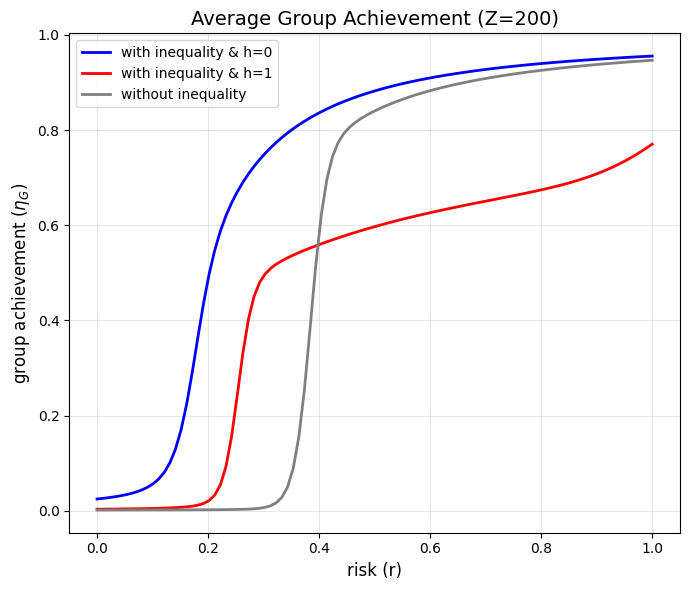


--- Generating Figure 2 ---
  Simulating Panel: r=0.2, h=0.0...
  Simulating Panel: r=0.2, h=0.7...
  Simulating Panel: r=0.2, h=1.0...
  Simulating Panel: r=0.3, h=0.0...
  Simulating Panel: r=0.3, h=0.7...
  Simulating Panel: r=0.3, h=1.0...


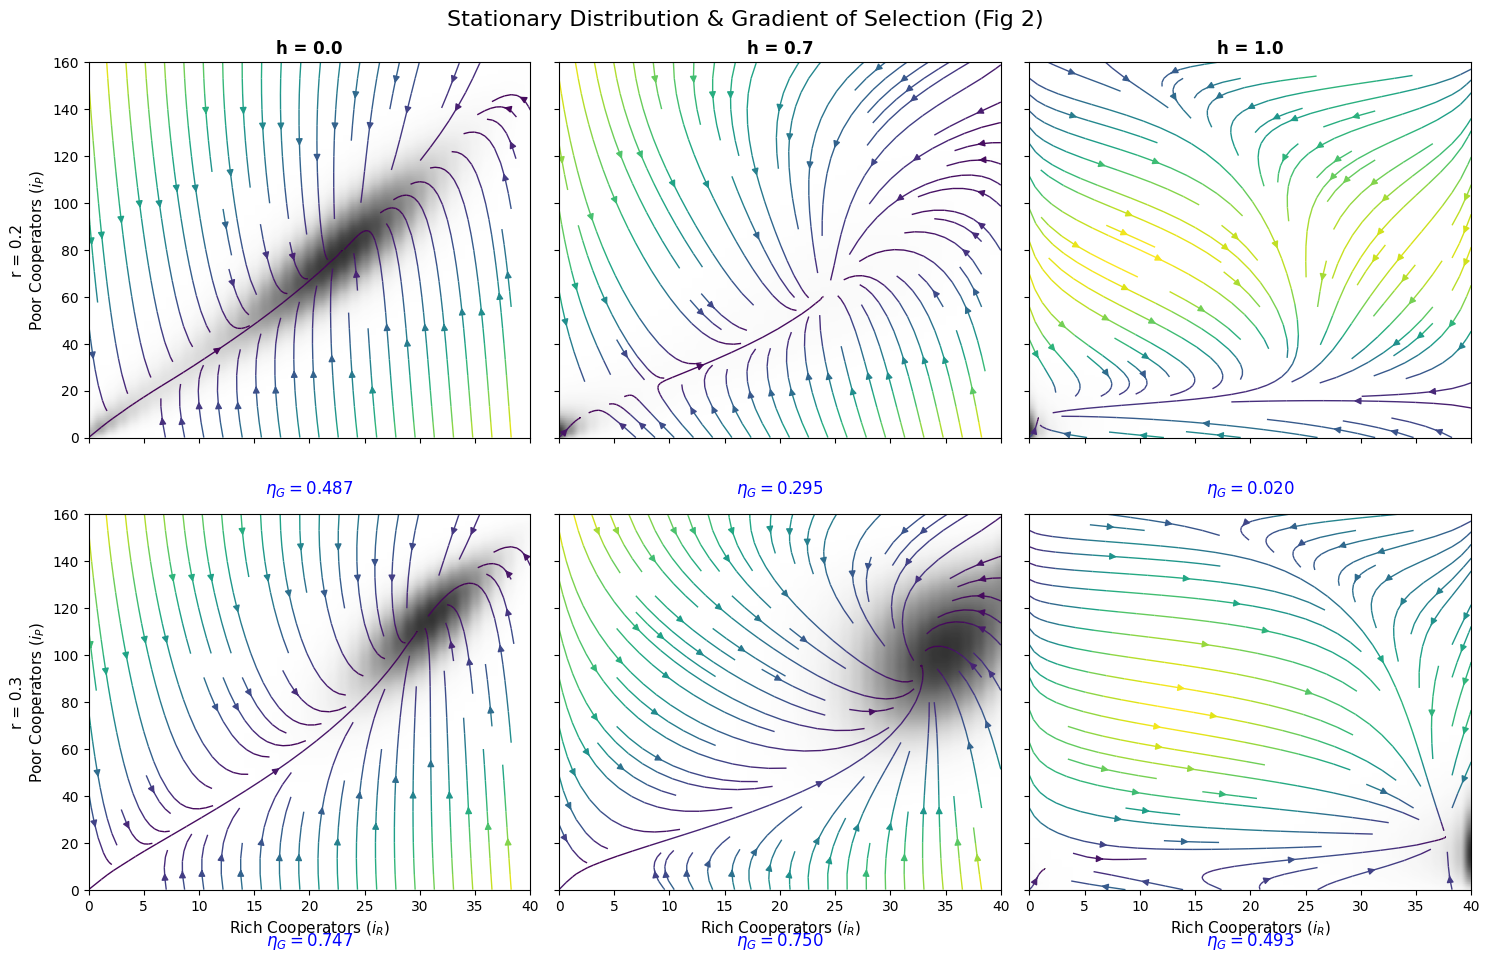

--- Reproducing Figure 3: Impact of Obstinate Behavior ---
Generating Panel A. No Obstinate...
Generating Panel B. Obstinate Rich (10%)...
Generating Panel C. Obstinate Poor (10%)...


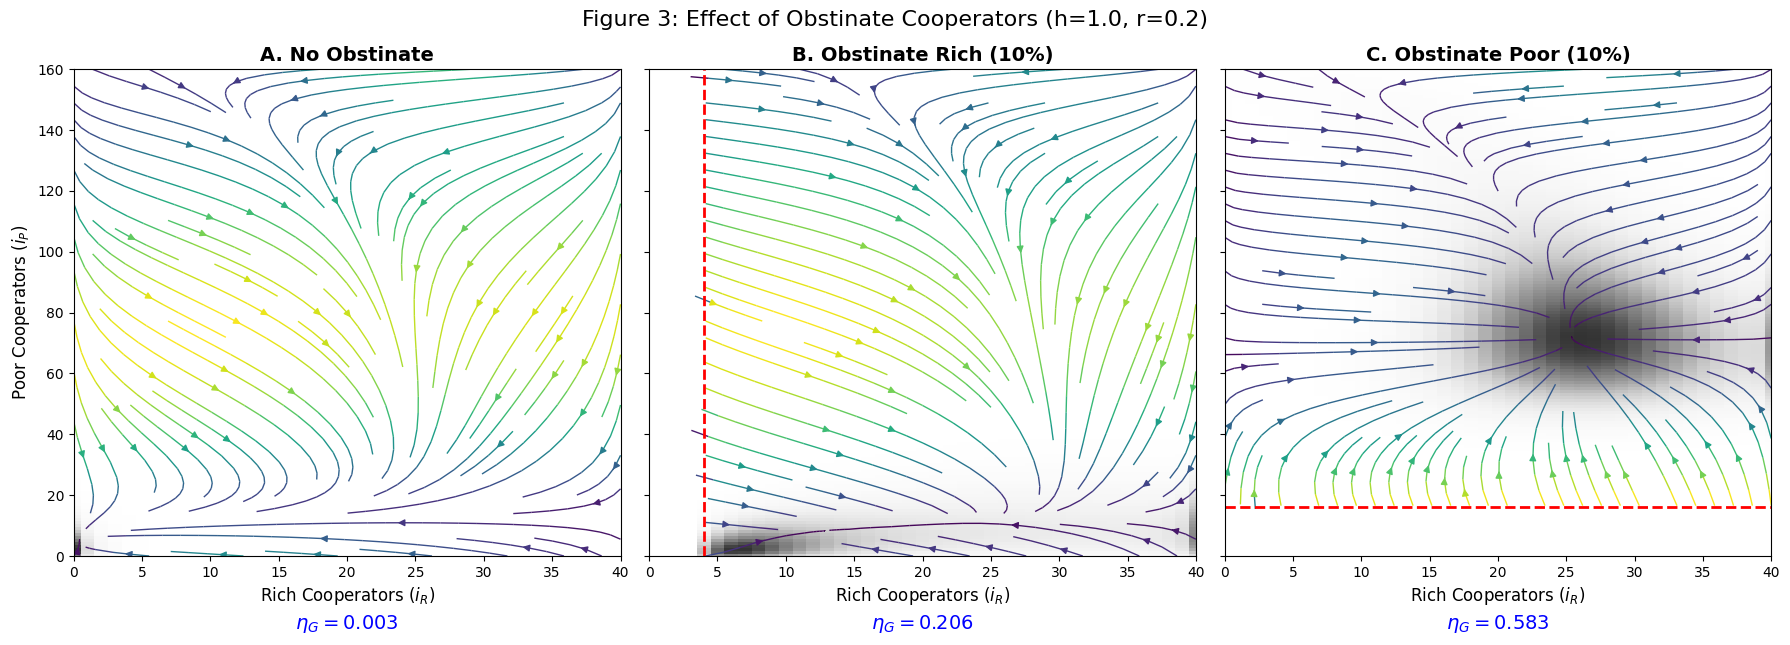

In [ ]:
SIMULATION_Z = 200
ZR_FRAC = 0.2
ZR_COUNT = int(SIMULATION_Z * ZR_FRAC)
ZP_COUNT = SIMULATION_Z - ZR_COUNT

def plot_figure_1():
    print("--- Generating Figure 1 ---")
    risks = np.linspace(0.0, 1.0, 100)
    
    eta_no_ineq = []
    eta_ineq_h0 = []
    eta_ineq_h1 = []

    print(f"Simulating Z={SIMULATION_Z} for {len(risks)} risk values...")

    for r in risks:
        # 1. Without Inequality (Gray Line)
        # bR = bP = 1.0.
        model_eq = PGG(Z=SIMULATION_Z, ZR=ZR_COUNT, bR=1.0, bP=1.0, h=0, r=r)
        dist_eq = model_eq.solve_stationary_distribution()
        eta_no_ineq.append(model_eq.calculate_eta_G(dist_eq))

        # 2. With Inequality, h=0 (Blue Line)
        model_h0 = PGG(Z=SIMULATION_Z, ZR=ZR_COUNT, bR=2.5, bP=0.625, h=0, r=r)
        dist_h0 = model_h0.solve_stationary_distribution()
        eta_ineq_h0.append(model_h0.calculate_eta_G(dist_h0))

        # 3. With Inequality, h=1 (Red Line)
        model_h1 = PGG(Z=SIMULATION_Z, ZR=ZR_COUNT, bR=2.5, bP=0.625, h=1, r=r)
        dist_h1 = model_h1.solve_stationary_distribution()
        eta_ineq_h1.append(model_h1.calculate_eta_G(dist_h1))
        
        print(f"  r={r:.2f} done.")

    plt.figure(figsize=(7, 6))
    plt.plot(risks, eta_ineq_h0, 'b-', linewidth=2, label='with inequality & h=0')
    plt.plot(risks, eta_ineq_h1, 'r-', linewidth=2, label='with inequality & h=1')
    plt.plot(risks, eta_no_ineq, 'gray', linewidth=2, label='without inequality')
    
    plt.xlabel('risk (r)', fontsize=12)
    plt.ylabel('group achievement ($\eta_G$)', fontsize=12)
    plt.title(f'Average Group Achievement (Z={SIMULATION_Z})', fontsize=14)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def plot_figure_2():
    print("\n--- Generating Figure 2 ---")
    risks = [0.2, 0.3]
    homophilies = [0.0, 0.7, 1.0]
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10), sharex=True, sharey=True)

    for i, r in enumerate(risks):
        for j, h in enumerate(homophilies):
            print(f"  Simulating Panel: r={r}, h={h}...")
            model = PGG(Z=SIMULATION_Z, ZR=ZR_COUNT, bR=2.5, bP=0.625, h=h, r=r)
            
            # Stationary Distribution
            dist = model.solve_stationary_distribution()
            eta = model.calculate_eta_G(dist)
            
            density_grid = np.zeros((model.ZP + 1, model.ZR + 1))
            for iR in range(model.ZR + 1):
                for iP in range(model.ZP + 1):
                    idx = iR * (model.ZP + 1) + iP
                    density_grid[iP, iR] = dist[idx]

            # Gradient Field
            iR_vals = np.arange(0, model.ZR + 1)
            iP_vals = np.arange(0, model.ZP + 1)
            X, Y = np.meshgrid(iR_vals, iP_vals)
            U = np.zeros_like(X, dtype=float)
            V = np.zeros_like(Y, dtype=float)

            # Gradient calculation loop
            for y_idx in range(len(iP_vals)):
                for x_idx in range(len(iR_vals)):
                    grad = model.calculate_gradient_of_selection(int(X[y_idx, x_idx]), int(Y[y_idx, x_idx]))
                    U[y_idx, x_idx] = grad[0]
                    V[y_idx, x_idx] = grad[1]

            speed = np.sqrt(U**2 + V**2)
            
            # Plotting
            ax = axes[i, j]
            
            # Heatmap
            ax.imshow(density_grid, origin='lower', cmap='Greys', aspect='auto', 
                      extent=[-0.5, model.ZR+0.5, -0.5, model.ZP+0.5], alpha=0.8)
            
            # Streamplot (Vector Field)
            ax.streamplot(X, Y, U, V, color=speed, cmap='viridis', density=0.8, linewidth=1)
            
            ax.set_xlim(0, model.ZR)
            ax.set_ylim(0, model.ZP)
            
            # Titles and Labels matching paper
            if i == 0: ax.set_title(f"h = {h}", fontsize=12, fontweight='bold')
            if j == 0: ax.set_ylabel(f"r = {r}\nPoor Cooperators ($i_P$)", fontsize=11)
            if i == 1: ax.set_xlabel("Rich Cooperators ($i_R$)", fontsize=11)
            
            # Display Eta_G in text
            ax.text(0.5, -0.15, f"$\eta_G = {eta:.3f}$", transform=ax.transAxes, 
                    ha='center', fontsize=12, color='blue')

    plt.suptitle("Stationary Distribution & Gradient of Selection (Fig 2)", fontsize=16)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.1) # Make room for eta labels
    plt.show()

def plot_figure_3():
    print("--- Reproducing Figure 3: Impact of Obstinate Behavior ---")
    
    PARAMS = {
        'Z': SIMULATION_Z, 'ZR': ZR_COUNT, 
        'bR': 2.5, 'bP': 0.625, 'c': 0.1, 'N': 6, 'M': 3,
        'beta': 5.0,
        'mu': 1/SIMULATION_Z,
        'h': 1.0,
        'r': 0.2 
    }

    # The scenarios
    scenarios = [
        {"label": "A. No Obstinate", "r_obs": 0.0, "p_obs": 0.0},
        {"label": "B. Obstinate Rich (10%)", "r_obs": 0.1, "p_obs": 0.0},
        {"label": "C. Obstinate Poor (10%)", "r_obs": 0.0, "p_obs": 0.1}
    ]

    fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharey=True)

    for idx, scen in enumerate(scenarios):
        print(f"Generating Panel {scen['label']}...")
        
        model = PGG(
            r_obs=scen['r_obs'], 
            p_obs=scen['p_obs'],
            **PARAMS
        )
        
        # Stationary Distribution (The Heatmap)
        dist = model.solve_stationary_distribution()
        eta = model.calculate_eta_G(dist)
        
        density_grid = np.zeros((model.ZP + 1, model.ZR + 1))
        for iR in range(model.ZR + 1):
            for iP in range(model.ZP + 1):
                flat_idx = iR * (model.ZP + 1) + iP
                density_grid[iP, iR] = dist[flat_idx]

        # Gradient Field
        iR_vals = np.arange(0, model.ZR + 1)
        iP_vals = np.arange(0, model.ZP + 1)
        X, Y = np.meshgrid(iR_vals, iP_vals)
        U = np.zeros_like(X, dtype=float)
        V = np.zeros_like(Y, dtype=float)
        
        for y_idx in range(len(iP_vals)):
            for x_idx in range(len(iR_vals)):
                # Skip gradients for impossible states
                if x_idx < model.r_obs_count or y_idx < model.p_obs_count:
                    continue
                    
                grad = model.calculate_gradient_of_selection(int(X[y_idx, x_idx]), int(Y[y_idx, x_idx]))
                U[y_idx, x_idx] = grad[0]
                V[y_idx, x_idx] = grad[1]
                
        speed = np.sqrt(U**2 + V**2)
        
        # Plotting
        ax = axes[idx]
        
        # Heatmap
        ax.imshow(density_grid, origin='lower', cmap='Greys', aspect='auto',
                  extent=[-0.5, model.ZR+0.5, -0.5, model.ZP+0.5], alpha=0.8)
        
        # Streamplot (Gradient Field)
        ax.streamplot(X, Y, U, V, color=speed, cmap='viridis', density=1.0, linewidth=1)
        
        # Visualizing the Obstinate Barrier
        if model.r_obs_count > 0:
            ax.axvline(model.r_obs_count, color='red', linestyle='--', linewidth=2, label='Obstinate')
        if model.p_obs_count > 0:
            ax.axhline(model.p_obs_count, color='red', linestyle='--', linewidth=2, label='Obstinate')
            
        # Formatting
        ax.set_title(scen['label'], fontsize=14, fontweight='bold')
        ax.set_xlabel("Rich Cooperators ($i_R$)", fontsize=12)
        if idx == 0:
            ax.set_ylabel("Poor Cooperators ($i_P$)", fontsize=12)
        
        ax.set_xlim(0, model.ZR)
        ax.set_ylim(0, model.ZP)
        
        # Display Group Achievement (Eta_G)
        ax.text(0.5, -0.15, f"$\eta_G = {eta:.3f}$", transform=ax.transAxes, 
                ha='center', fontsize=14, color='blue')

    plt.suptitle("Figure 3: Effect of Obstinate Cooperators (h=1.0, r=0.2)", fontsize=16, y=0.98)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.2) # Make room for eta labels
    plt.show()

plot_figure_1()
plot_figure_2()
plot_figure_3()